# Classifier for fish Calls


In [104]:
import torch
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import torch.optim as optim
import torch.nn as nn
from torch.utils.data import random_split
import torch.nn.functional as F
import random

import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### Loading the Fake Data

In [105]:
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1), #ensures 1-channel
    transforms.ToTensor(), # changes pixels and shape
    transforms.Normalize(mean=[0.5], std=[0.5])
])

bad_dataset = datasets.ImageFolder(
    root="D:/POTENTIAL Fish sounds/random_snips",
    transform=transform
)

loader_bad = DataLoader(bad_dataset, batch_size=16, shuffle=True) #Bigger is better - probably?

In [106]:
print(bad_dataset.class_to_idx)

{'z': 0}


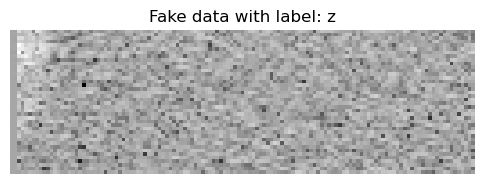

In [107]:
imgs, labels = next(iter(loader_bad))

img = imgs[0]
label_indx = labels[0].item()
img_np = img.squeeze().numpy()

plt.figure(figsize=(6,4))
plt.imshow(img_np, cmap='gray')
plt.title(f"Fake data with label: {bad_dataset.classes[label_indx]}")
plt.axis('off')
plt.show()

### Loading the Good Data: 

In [108]:
good_dataset = datasets.ImageFolder(
    root="D:/POTENTIAL Fish sounds/cnn_snips",
    transform=transform
)


train_size = int(0.8 * len(good_dataset))
val_size = len(good_dataset) - train_size

train_dataset, val_dataset = random_split(good_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

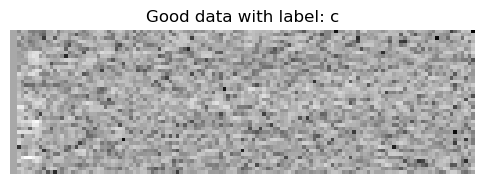

In [109]:
imgs, labels = next(iter(train_loader))

img = imgs[0]
label_indx = labels[0].item()
img_np = img.squeeze().numpy()

plt.figure(figsize=(6,4))
plt.imshow(img_np, cmap='gray')
plt.title(f"Good data with label: {good_dataset.classes[label_indx]}")
plt.axis('off')
plt.show()

### Initializing CNN

In [110]:
import torch
import random
import torch.nn.functional as F

def augment_spectrogram(x):
    B, C, Freq, Time = x.shape

    # ----- 1. Time masking -----
    if random.random() < 0.7:
        t = random.randint(10, 40)
        t0 = random.randint(0, max(1, Time - t))
        x[:, :, :, t0:t0+t] = 0

    # ----- 2. Frequency masking -----
    if random.random() < 0.7:
        f = random.randint(5, 15)
        f0 = random.randint(0, max(1, Freq - f))
        x[:, :, f0:f0+f, :] = 0

    # ----- 3. Time shift -----
    if random.random() < 0.7:
        shift = random.randint(-20, 20)
        x = torch.roll(x, shifts=shift, dims=-1)


    # ----- 5. Random gain -----
    if random.random() < 0.7:
        gain = 0.7 + 0.6 * random.random()   # 0.7–1.3
        x = x * gain

    # ----- 6. Additive Gaussian noise -----
    if random.random() < 0.7:
        noise = 0.015 * torch.randn_like(x)
        x = x + noise




    return x


class ProjectionHead(nn.Module):
    def __init__(self, in_dim=512, proj_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 256),
            nn.ReLU(),
            nn.Linear(256, proj_dim)
        )

    def forward(self, x):
        return self.net(x)

from torchvision.models import mobilenet_v3_small

class SimCLR(nn.Module):
    def __init__(self):
        super().__init__()
        base = mobilenet_v3_small(weights=None)
        base.features[0][0] = nn.Conv2d(1, 16, 3, 2, 1, bias=False)
        self.encoder = base.features
        self.pool = nn.AdaptiveAvgPool2d((1,1))
        self.projector = ProjectionHead(in_dim=576, proj_dim=128)

    def forward(self, x):
        h = self.encoder(x)
        h = self.pool(h).flatten(1)
        z = self.projector(h)
        return F.normalize(z, dim=1)

def nt_xent_loss(z1, z2, temperature=0.5):
    B = z1.size(0)
    z = torch.cat([z1, z2], dim=0)  # [2B, D]

    sim = torch.matmul(z, z.T) / temperature
    mask = torch.eye(2*B, device=z.device).bool()
    sim = sim.masked_fill(mask, -9e15)

    positives = torch.cat([torch.arange(B, 2*B), torch.arange(0, B)]).to(z.device)
    loss = F.cross_entropy(sim, positives)
    return loss


class ResNet18SimCLR(nn.Module):
    def __init__(self):
        super().__init__()
        base = resnet18(weights=None)

        # 1‑channel input
        base.conv1 = nn.Conv2d(1, 64, 3, stride=1, padding=1, bias=False)

        self.encoder = nn.Sequential(*list(base.children())[:-1])  # remove FC
        self.projector = ProjectionHead(in_dim=512, proj_dim=128)

    def forward(self, x):
        h = self.encoder(x)          # [B, 512, 1, 1]
        h = h.flatten(1)             # [B, 512]
        z = self.projector(h)        # [B, 128]
        return F.normalize(z, dim=1)


### Perform Pretraining

In [111]:
from torchvision.models import resnet18


def pretrain_simclr(model, loader, optimizer, epochs=50):
    model.train()
    for epoch in range(epochs):
        total_loss = 0
        for imgs, _ in loader:
            imgs = imgs.to(device)

            x1 = augment_spectrogram(imgs.clone())
            x2 = augment_spectrogram(imgs.clone())

            z1 = model(x1)
            z2 = model(x2)

            loss = nt_xent_loss(z1, z2)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs}  Contrastive Loss: {total_loss/len(loader):.4f}")

simclr = ResNet18SimCLR().to(device)
optimizer = torch.optim.Adam(simclr.parameters(), lr=1e-3)

pretrain_simclr(simclr, loader_bad, optimizer, epochs=30)

torch.save(simclr.encoder.state_dict(), "simclr_resnet18_encoder.pth")


Epoch 1/30  Contrastive Loss: 2.0594
Epoch 2/30  Contrastive Loss: 1.8814
Epoch 3/30  Contrastive Loss: 1.8328
Epoch 4/30  Contrastive Loss: 1.8081
Epoch 5/30  Contrastive Loss: 1.8146
Epoch 6/30  Contrastive Loss: 1.7759
Epoch 7/30  Contrastive Loss: 1.7817
Epoch 8/30  Contrastive Loss: 1.7696
Epoch 9/30  Contrastive Loss: 1.7460
Epoch 10/30  Contrastive Loss: 1.7387
Epoch 11/30  Contrastive Loss: 1.7311
Epoch 12/30  Contrastive Loss: 1.7384
Epoch 13/30  Contrastive Loss: 1.7120
Epoch 14/30  Contrastive Loss: 1.7078
Epoch 15/30  Contrastive Loss: 1.7009
Epoch 16/30  Contrastive Loss: 1.7059
Epoch 17/30  Contrastive Loss: 1.7213
Epoch 18/30  Contrastive Loss: 1.6981
Epoch 19/30  Contrastive Loss: 1.7074
Epoch 20/30  Contrastive Loss: 1.6901
Epoch 21/30  Contrastive Loss: 1.7169
Epoch 22/30  Contrastive Loss: 1.6944
Epoch 23/30  Contrastive Loss: 1.6921
Epoch 24/30  Contrastive Loss: 1.6948
Epoch 25/30  Contrastive Loss: 1.7006
Epoch 26/30  Contrastive Loss: 1.6812
Epoch 27/30  Contrast

### Actual Training: 

In [112]:
def fit(model, train_loader, optimizer, criterion, epochs, val_loader=None, scheduler=None):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for imgs, labels in train_loader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        if scheduler is not None:
            scheduler.step()

        print(f"Epoch {epoch+1}/{epochs}  Train Loss: {total_loss/len(train_loader):.4f}")

        # Optional validation
        if val_loader is not None:
            model.eval()
            correct = 0
            total = 0
            with torch.no_grad():
                for imgs, labels in val_loader:
                    imgs = imgs.to(device)
                    labels = labels.to(device)
                    preds = model(imgs).argmax(dim=1)
                    correct += (preds == labels).sum().item()
                    total += labels.size(0)
            acc = correct / total
            print(f"  Val Acc: {acc:.4f}")
            model.train()

# -----------------------------
# Build model for tiny dataset
# -----------------------------
base = resnet18(weights=None)
base.conv1 = nn.Conv2d(1, 64, 3, stride=1, padding=1, bias=False)

# Extract encoder (everything except final FC)
encoder = nn.Sequential(*list(base.children())[:-1])

# Freeze encoder
for p in encoder.parameters():
    p.requires_grad = False

# Build classifier
class FineTuneModel(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.fc = nn.Linear(512, 5)   # tiny head for tiny dataset

    def forward(self, x):
        h = self.encoder(x)           # [B, 512, 1, 1]
        h = h.flatten(1)              # [B, 512]
        return self.fc(h)

finetune_model = FineTuneModel(encoder).to(device)



criterion = nn.CrossEntropyLoss(label_smoothing=0.1) #try more loss methods

optimizer = torch.optim.Adam(finetune_model.fc.parameters(), lr=1e-3)


scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=50, eta_min=1e-6
)

fit(
    finetune_model,
    train_loader,
    optimizer,
    criterion,
    epochs=30,
    val_loader=val_loader,
    scheduler=scheduler
)


Epoch 1/30  Train Loss: 1.4067
  Val Acc: 0.4286
Epoch 2/30  Train Loss: 1.3277
  Val Acc: 0.4286
Epoch 3/30  Train Loss: 1.3254
  Val Acc: 0.4490
Epoch 4/30  Train Loss: 1.3081
  Val Acc: 0.4286
Epoch 5/30  Train Loss: 1.3294
  Val Acc: 0.4694
Epoch 6/30  Train Loss: 1.3339
  Val Acc: 0.3265
Epoch 7/30  Train Loss: 1.3059
  Val Acc: 0.4490
Epoch 8/30  Train Loss: 1.3321
  Val Acc: 0.4490
Epoch 9/30  Train Loss: 1.2853
  Val Acc: 0.4490
Epoch 10/30  Train Loss: 1.3533
  Val Acc: 0.4898
Epoch 11/30  Train Loss: 1.2929
  Val Acc: 0.4286
Epoch 12/30  Train Loss: 1.3296
  Val Acc: 0.4898
Epoch 13/30  Train Loss: 1.3001
  Val Acc: 0.5102
Epoch 14/30  Train Loss: 1.3054
  Val Acc: 0.4898
Epoch 15/30  Train Loss: 1.2891
  Val Acc: 0.4694
Epoch 16/30  Train Loss: 1.3063
  Val Acc: 0.4898
Epoch 17/30  Train Loss: 1.2552
  Val Acc: 0.4898
Epoch 18/30  Train Loss: 1.2375
  Val Acc: 0.5102
Epoch 19/30  Train Loss: 1.2260
  Val Acc: 0.5102
Epoch 20/30  Train Loss: 1.2300
  Val Acc: 0.5102
Epoch 21/

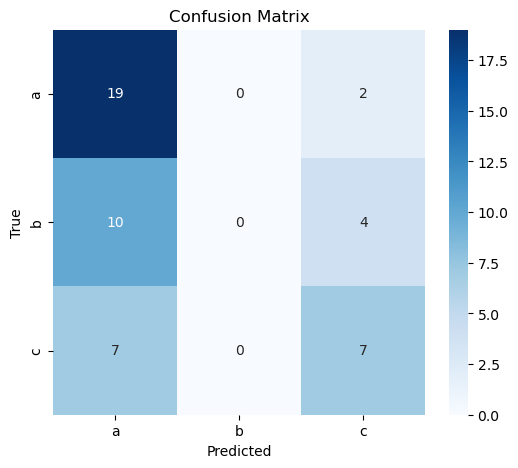

In [113]:
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

def get_predictions(model, loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            outputs = model(imgs)
            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return np.array(all_labels), np.array(all_preds)

y_true, y_pred = get_predictions(finetune_model, val_loader)
# keep only classes 0, 1, 2
mask = y_true < 3

y_true_filtered = y_true[mask]
y_pred_filtered = y_pred[mask]

cm = confusion_matrix(y_true_filtered, y_pred_filtered)

class_names = ["a", "b", "c"]  # adjust if needed

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()
